# 05. Сравнение методов


In [1]:
knitr::opts_chunk$set(
  echo = FALSE,
  message = FALSE,
  warning = FALSE,
  fig.align = "center",
  fig.width = 9,
  fig.height = 5
)


# О документе

Сравниваем оценку только по связям, оценку с панелью и истинный `true_value`.

| | |
|---|---|
| **Данные** | `data/lineage.csv`, `data/measurements.csv`, `data/markers.csv`, `data/reference.csv` |
| **Цель** | Согласованность методов: Спирмен, Манна–Уитни, Бланд–Альтман |
| **Результат** | Насколько панель меняет ранжирование изделий |


In [2]:
library(rrBLUP)
library(AGHmatrix)
library(Matrix)
library(pedigreeTools)
library(dplyr)
library(ggplot2)
library(tidyr)
library(stringr)
library(e1071)
library(knitr)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



In [3]:
z_score_filter <- function(pipeline, threshold) {
  z <- abs((pipeline$trait - mean(pipeline$trait, na.rm = TRUE)) / sd(pipeline$trait, na.rm = TRUE))
  pipeline %>% filter(!(z > threshold))
}

bending <- function(matrix, epsilon) {
  e <- eigen(matrix)
  e$values[e$values < epsilon] <- epsilon
  out <- e$vectors %*% diag(e$values) %*% t(e$vectors)
  rownames(out) <- rownames(matrix)
  colnames(out) <- colnames(matrix)
  out
}

scale_g_to_a <- function(A_matrix, G_matrix) {
  common <- intersect(rownames(G_matrix), rownames(A_matrix))
  G_matrix <- G_matrix[common, common, drop = FALSE]
  A22 <- A_matrix[common, common, drop = FALSE]
  G_matrix * (sum(diag(A22)) / sum(diag(G_matrix)))
}

prepare_ids <- function(lineage, measurements, markers = NULL) {
  ids <- unique(c(measurements$item_id, lineage$item_id, lineage$parent_a, lineage$parent_b))
  if (!is.null(markers)) ids <- unique(c(ids, markers$item_id))
  ids <- ids[ids != 0]
  levels <- as.character(sort(unique(ids)))
  recode <- function(x) as.integer(factor(as.character(x), levels = levels))
  lineage <- lineage %>%
    mutate(
      item_id = recode(item_id),
      parent_a = ifelse(parent_a == 0, 0L, recode(parent_a)),
      parent_b = ifelse(parent_b == 0, 0L, recode(parent_b))
    )
  measurements <- measurements %>% mutate(item_id = recode(item_id))
  if (!is.null(markers)) {
    markers <- markers %>% mutate(item_id = recode(item_id))
  }
  list(lineage = lineage, measurements = measurements, markers = markers, levels = levels)
}

order_lineage <- function(lineage, keep_ids) {
  ped <- editPed(label = lineage$item_id, sire = lineage$parent_a, dam = lineage$parent_b)
  ped <- ped[, c("label", "sire", "dam")]
  names(ped) <- c("item_id", "parent_a", "parent_b")
  ped <- ped %>% filter(item_id %in% keep_ids)
  ped$parent_a[!(ped$parent_a %in% ped$item_id)] <- 0
  ped$parent_b[!(ped$parent_b %in% ped$item_id)] <- 0
  rownames(ped) <- ped$item_id
  ped
}


In [4]:
measurements <- read.csv("data/measurements.csv") %>%
  dplyr::select(item_id, batch_mass, batch_no, line_age, event_season, event_year, trait)
markers <- read.csv("data/markers.csv", colClasses = c(item_id = "character", panel = "character"))
lineage <- read.csv("data/lineage.csv")
reference <- read.csv("data/reference.csv")
measurements <- z_score_filter(measurements, 2) %>% drop_na()
prep <- prepare_ids(lineage, measurements, markers)
lineage_bl <- order_lineage(prep$lineage, prep$measurements$item_id)
meas_bl <- prep$measurements %>%
  mutate(event_season = factor(event_season), event_year = factor(event_year))
mark_bl <- prep$markers
A <- Amatrix(lineage_bl[, c("item_id", "parent_a", "parent_b")], ploidy = 2)
if (nrow(A) == nrow(lineage_bl)) {
  rownames(A) <- as.character(lineage_bl$item_id)
  colnames(A) <- as.character(lineage_bl$item_id)
} else {
  rownames(A) <- as.character(rownames(A))
  colnames(A) <- as.character(colnames(A))
}
meas_bl <- meas_bl[as.character(meas_bl$item_id) %in% rownames(A), ]
meas_bl <- meas_bl[order(match(as.character(meas_bl$item_id), rownames(A))), ]
X <- model.matrix(~ line_age + batch_mass + batch_no + event_season + event_year, data = meas_bl)
Z <- model.matrix(~ 0 + factor(item_id, levels = rownames(A)), data = meas_bl)
colnames(Z) <- rownames(A)
res_a <- mixed.solve(y = meas_bl$trait, X = X, Z = Z, K = A)
M <- t(sapply(mark_bl$panel, function(x) as.numeric(strsplit(x, "")[[1]])))
rownames(M) <- as.character(mark_bl$item_id)
G <- scale_g_to_a(A, A.mat(as.matrix(M)))
common <- intersect(rownames(G), rownames(A))
G <- G[common, common]
H <- A
H[common, common] <- A[common, common] + (G - A[common, common])
res_h <- mixed.solve(y = meas_bl$trait, X = X, Z = Z, K = bending((H + t(H)) / 2, 1e-6))
u_a <- as.numeric(res_a$u)
u_h <- as.numeric(res_h$u)
n_u <- min(length(u_a), length(u_h))
cmp <- data.frame(
  item_id = as.integer(prep$levels[as.integer(colnames(Z)[seq_len(n_u)])]),
  est_a = u_a[seq_len(n_u)],
  est_h = u_h[seq_len(n_u)]
) %>%
  left_join(reference, by = "item_id")
head(cmp)


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 8.333333e-05  minutes 


  item_id         est_a         est_h true_value  rel_true
1       1  1.782789e-10  0.0001865859  0.9479520 0.5133597
2       2  1.356258e-09  0.0015391057 -1.2015824 0.4542187
3       3 -1.208023e-09 -0.0012864365 -0.4661161 0.6820742
4       4  9.988872e-10  0.0009895262 -0.2693514 0.7878039
5       5 -1.233821e-09 -0.0011370524 -0.3909654 0.7189251
6       6 -1.234008e-09 -0.0011716309  1.3487070 0.4257662


# 1. Корреляции и сдвиг


In [5]:
data.frame(
  pair = c("A vs H", "A vs true", "H vs true"),
  spearman = c(
    cor(cmp$est_a, cmp$est_h, method = "spearman"),
    cor(cmp$est_a, cmp$true_value, method = "spearman"),
    cor(cmp$est_h, cmp$true_value, method = "spearman")
  )
)


       pair  spearman
1    A vs H 0.8859680
2 A vs true 0.4541380
3 H vs true 0.4557598


In [6]:
wilcox.test(cmp$est_a, cmp$est_h, paired = TRUE)



	Wilcoxon signed rank test with continuity correction

data:  cmp$est_a and cmp$est_h
V = 8485, p-value = 0.4393
alternative hypothesis: true location shift is not equal to 0



# 2. Бланд–Альтман: A против H


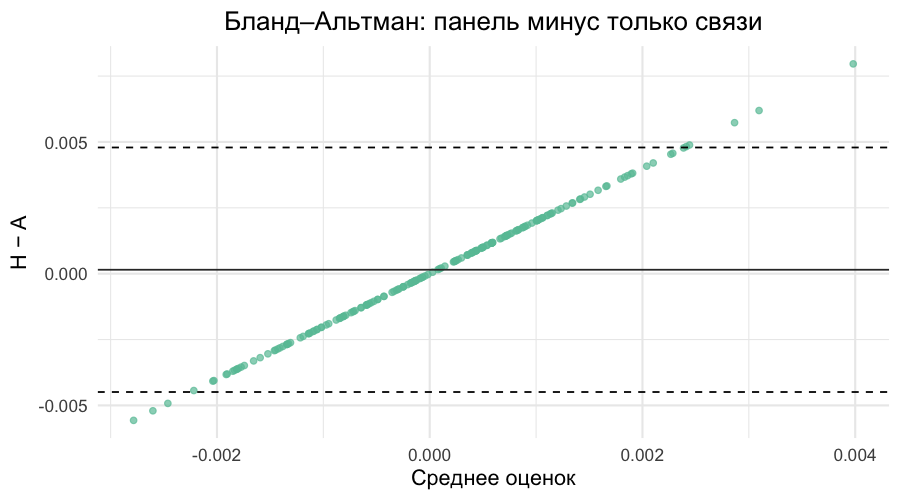

In [7]:
ba <- data.frame(
  mean = (cmp$est_a + cmp$est_h) / 2,
  diff = cmp$est_h - cmp$est_a
)
ggplot(ba, aes(x = mean, y = diff)) +
  geom_point(alpha = 0.7, color = "#66C2A5") +
  geom_hline(yintercept = mean(ba$diff), color = "grey20") +
  geom_hline(yintercept = mean(ba$diff) + c(-1.96, 1.96) * sd(ba$diff), linetype = "dashed") +
  labs(title = "Бланд–Альтман: панель минус только связи", x = "Среднее оценок", y = "H − A") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


`geom_smooth()` using formula = 'y ~ x'


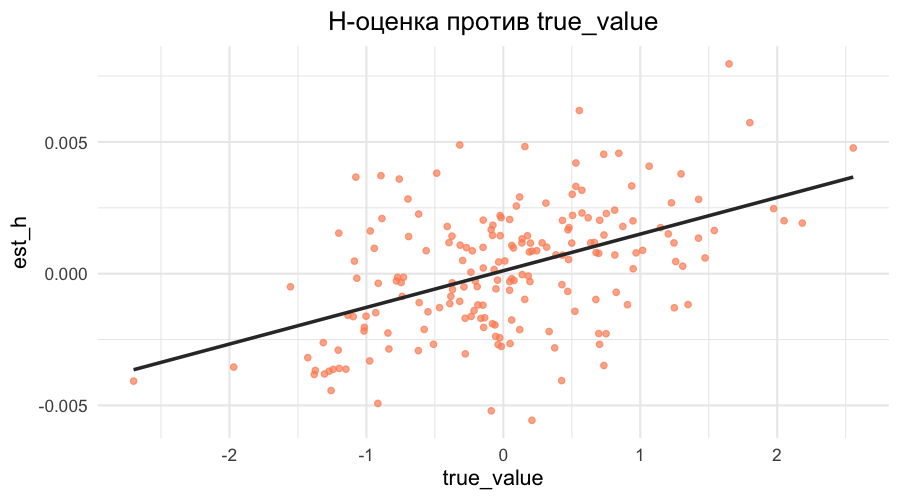

In [8]:
ggplot(cmp, aes(x = true_value, y = est_h)) +
  geom_point(alpha = 0.7, color = "#FC8D62") +
  geom_smooth(method = "lm", se = FALSE, color = "grey20") +
  labs(title = "H-оценка против true_value", x = "true_value", y = "est_h") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5))


# Заключение

Если Спирмен A–H близок к 1, панель почти не меняет порядок изделий. Имеет смысл смотреть хвосты Бланда–Альтмана: там, где H уходит от A, как раз изделия с панелью и расхождение связей с маркерами.
